
# SBP/SAT Entropy-Stable DGSEM Scaffold — Burgers' Equation

This notebook is a runnable companion to *My Rough Notes*, built to actually carry out the
"go run your own numerics" step that Section 6 of those notes flags as still outstanding.

It follows the exact build order discussed for the project: get the reference-element operators
right and check their algebraic (SBP) property first, then work up through linear advection,
Burgers with a naive (aliasing-prone) scheme, Burgers with the entropy-conservative flux-differencing
fix, a genuine long-time stability/blow-up comparison between the two, and finally a small shock-tube
comparison of Roe vs. Godunov reproducing the notes' own worked example (Section 2).

Burgers' equation is the right first target for exactly the reason the notes keep returning to it:
it's the smallest equation with genuine flux nonlinearity (so it can actually form a shock and expose
entropy issues, unlike linear advection), and it has closed-form entropy pair $U=u^2/2$,
$\psi=u^3/3$, and a closed-form entropy-conservative two-point flux — so every check below has a
hand-computable right answer to test against, rather than trusting the code blind.

**Structure**

1. Reference element: LGL nodes, Lagrange differentiation matrix, and the SBP identity
2. Linear advection: method-of-lines + RK4, convergence test
3. Burgers, naive scheme: reproduces the notes' own $N=2$ aliasing counterexample exactly
4. Burgers, entropy-conservative flux differencing: verifies the exact telescoping identity
5. Multi-element assembly + a genuine stability experiment: naive scheme blows up, EC scheme doesn't
6. Shock tube: Roe vs. Godunov on admissible vs. inadmissible Riemann data

A note on notation before we start: throughout, $\beta(u)=U'(u)$ is the entropy variable and
$\psi(u)$ is the physical entropy flux — for Burgers, $\beta=u$ and $\psi=u^3/3$. (One thing this
notebook caught: the PDF notes' Example 4.1 labels its boundary-difference comparison "$\Phi$", but
the numbers it quotes are actually $\psi$, not the flux potential $\Phi=\beta F-\psi$. The arithmetic
in the notes is right; the label is a leftover from the source paper and is worth fixing there — this
notebook uses $\psi$, the mathematically correct comparison target, throughout.)



## 1. The Reference Element: LGL Nodes, Differentiation Matrix, SBP Identity

Everything downstream depends on having a correct set of nodes $\{\xi_j\}$, weights $\{w_j\}$
(the diagonal mass matrix $M$), and a differentiation matrix $D$ satisfying the discrete
integration-by-parts identity

$$MD + D^\top M = R^\top B R,$$

where $R$ restricts a nodal vector to the two boundary nodes and $B=\mathrm{diag}(-1,+1)$ carries
the sign of the outward normal (Definition 1.10 / Lemma 3.11 in the notes). We build
Legendre–Gauss–Lobatto (LGL) nodes since they include the endpoints, which is what makes the
boundary terms in the DG scheme trivial to extract later (Section 1.12's remark on node choice).

**LGL nodes and weights.** For degree $N$ ($N{+}1$ points), the interior nodes are the roots of
$P_N'(\xi)$ (the derivative of the Legendre polynomial), with $\xi_0=-1,\xi_N=1$ fixed. We find
them by a short Newton iteration on the Legendre recurrence — standard and self-contained, no
special-function library needed. The weights are $w_j = \dfrac{2}{N(N+1)[P_N(\xi_j)]^2}$.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

def lgl_nodes_weights(N):
    '''Legendre-Gauss-Lobatto nodes and weights on [-1, 1] for degree N (N+1 points).'''
    n = N + 1
    x = np.cos(np.pi * np.arange(n) / N)  # Chebyshev points as the initial guess
    P = np.zeros((n, n))
    x_old = np.ones(n) * 2
    it = 0
    while np.max(np.abs(x - x_old)) > 1e-15 and it < 200:
        x_old = x.copy()
        P[:, 0] = 1.0
        P[:, 1] = x
        for k in range(2, n):
            P[:, k] = ((2*k - 1) * x * P[:, k-1] - (k-1) * P[:, k-2]) / k
        # Newton update using the known ODE identity for P_N'
        x = x_old - (x * P[:, N] - P[:, N-1]) / (n * P[:, N])
        it += 1
    x = np.sort(x)
    P = np.zeros((n, n))
    P[:, 0] = 1.0
    P[:, 1] = x
    for k in range(2, n):
        P[:, k] = ((2*k - 1) * x * P[:, k-1] - (k-1) * P[:, k-2]) / k
    w = 2.0 / (N * (N+1) * P[:, N]**2)
    return x, w

# sanity check against the N=2 case worked by hand in the notes: nodes (-1,0,1), weights (1/3,4/3,1/3)
x2, w2 = lgl_nodes_weights(2)
print("N=2 nodes: ", x2, "  (expect [-1, 0, 1])")
print("N=2 weights:", w2, " (expect [1/3, 4/3, 1/3])")


N=2 nodes:  [-1.  0.  1.]   (expect [-1, 0, 1])
N=2 weights: [0.33333333 1.33333333 0.33333333]  (expect [1/3, 4/3, 1/3])


In [2]:

def diff_matrix(x):
    '''Lagrange differentiation matrix on nodes x, via barycentric weights (Trefethen's formula).'''
    n = len(x)
    c = np.array([np.prod([x[i]-x[j] for j in range(n) if j != i]) for i in range(n)])
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                D[i, j] = (c[i]/c[j]) / (x[i]-x[j])
    for i in range(n):
        D[i, i] = -np.sum(D[i, :])   # "negative sum trick": exact for the constant function
    return D

D2 = diff_matrix(x2)
print("N=2 differentiation matrix D:")
print(D2)
print("\nCompare with the notes' Example 4.1 matrix:")
print(np.array([[-1.5, 2, -0.5], [-0.5, 0, 0.5], [0.5, -2, 1.5]]))


N=2 differentiation matrix D:
[[-1.5  2.  -0.5]
 [-0.5 -0.   0.5]
 [ 0.5 -2.   1.5]]

Compare with the notes' Example 4.1 matrix:
[[-1.5  2.  -0.5]
 [-0.5  0.   0.5]
 [ 0.5 -2.   1.5]]


In [3]:

# The SBP identity itself: M D + D^T M == R^T B R, exactly (to floating point), for every N.
def sbp_check(N):
    x, w = lgl_nodes_weights(N)
    D = diff_matrix(x)
    M = np.diag(w)
    R = np.zeros((2, N+1)); R[0, 0] = 1.0; R[1, -1] = 1.0
    B = np.diag([-1.0, 1.0])
    lhs = M @ D + D.T @ M
    rhs = R.T @ B @ R
    return np.max(np.abs(lhs - rhs))

print("Definition 1.10's SBP identity, checked for several polynomial degrees N:")
for N in [1, 2, 3, 4, 8, 16]:
    err = sbp_check(N)
    print(f"  N={N:2d}:  max |MD + D^T M - R^T B R| = {err:.3e}")
print("\nAll zero to floating-point precision -- this is the property everything else in the")
print("notes (Section 3 onward) is built on. If this check ever fails, nothing downstream will work.")


Definition 1.10's SBP identity, checked for several polynomial degrees N:
  N= 1:  max |MD + D^T M - R^T B R| = 0.000e+00
  N= 2:  max |MD + D^T M - R^T B R| = 0.000e+00
  N= 3:  max |MD + D^T M - R^T B R| = 3.331e-16
  N= 4:  max |MD + D^T M - R^T B R| = 1.028e-15
  N= 8:  max |MD + D^T M - R^T B R| = 1.727e-15
  N=16:  max |MD + D^T M - R^T B R| = 1.092e-14

All zero to floating-point precision -- this is the property everything else in the
notes (Section 3 onward) is built on. If this check ever fails, nothing downstream will work.



## 2. Linear Advection: Method of Lines + RK4, Convergence Test

Before touching anything nonlinear, check that the basic DG machinery -- multi-element assembly,
the numerical-flux coupling at interfaces, and time integration -- is actually correct. Linear
advection $u_t + au_x = 0$ has no aliasing issues (the flux is linear in $u$, so "collocate then
multiply" is exact), so this test isolates *only* the DG plumbing, not the entropy-stability
questions that come later.

We use the strong form from Section 3.8 of the notes,
$$
\partial_t u = -J^{-1}Du - M_{\mathrm{phys}}^{-1}R^\top B\big(f^{\mathrm{num}} - Rf\big),
$$
with the mesh split into $K$ periodic elements, each an affinely-mapped copy of the LGL reference
element (constant Jacobian $J=h/2$ per element, $h$ = element width), coupled by upwinding.
The expected result, since polynomials of degree $N$ approximate smooth functions to order $N{+}1$,
is convergence at rate $N{+}1$ under mesh refinement.


In [4]:

class Mesh1D:
    '''A periodic 1D mesh of K affinely-mapped LGL elements of polynomial degree N.'''
    def __init__(self, xL, xR, K, N):
        self.K, self.N = K, N
        self.xi, self.w = lgl_nodes_weights(N)
        self.D = diff_matrix(self.xi)
        h = (xR - xL) / K
        self.h = h
        self.J = h / 2.0  # constant per element for an affine map
        self.x = np.zeros((K, N+1))
        for e in range(K):
            x0 = xL + e*h
            self.x[e, :] = x0 + (self.xi + 1) * 0.5 * h

def rk4_step(u, dt, rhs_fn):
    k1 = rhs_fn(u)
    k2 = rhs_fn(u + 0.5*dt*k1)
    k3 = rhs_fn(u + 0.5*dt*k2)
    k4 = rhs_fn(u + dt*k3)
    return u + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)


In [5]:

def rhs_advect(u, mesh, a=1.0):
    '''Strong-form SBP-SAT scheme for u_t + a u_x = 0, periodic, upwind coupling.'''
    K, N = mesh.K, mesh.N
    D, w, J = mesh.D, mesh.w, mesh.J
    du = np.zeros_like(u)
    for e in range(K):
        VOL = a * (D @ u[e])                       # linear flux: no aliasing issue here
        uL_out = u[(e-1) % K][-1]                   # left neighbour's boundary value
        uR_out = u[(e+1) % K][0]                    # right neighbour's boundary value
        f_left  = a*uL_out if a >= 0 else a*u[e][0]  # upwind numerical flux
        f_right = a*u[e][-1] if a >= 0 else a*uR_out
        du[e] = -(1.0/J) * VOL
        du[e][0]  += (1.0/(J*w[0]))  * (f_left  - a*u[e][0])
        du[e][-1] -= (1.0/(J*w[-1])) * (f_right - a*u[e][-1])
    return du

def run_advect(K, N, T=2.0, a=1.0):
    mesh = Mesh1D(-1, 1, K, N)
    u = np.sin(np.pi * mesh.x)
    dt = 0.2 * mesh.h / (N**2 + 1)
    nsteps = int(np.ceil(T/dt)); dt = T/nsteps
    for _ in range(nsteps):
        u = rk4_step(u, dt, lambda uu: rhs_advect(uu, mesh, a))
    exact = np.sin(np.pi * (mesh.x - a*T))
    return np.sqrt(np.sum(mesh.w[None, :] * mesh.J * (u - exact)**2))  # L2 error

print(f"{'N':>3} | {'K=4':>10} {'K=8':>10} {'K=16':>10} | {'rate 4->8':>10} {'rate 8->16':>11} | expected")
for N in [1, 2, 3, 4]:
    errs = [run_advect(K, N) for K in [4, 8, 16]]
    r1 = np.log(errs[0]/errs[1]) / np.log(2)
    r2 = np.log(errs[1]/errs[2]) / np.log(2)
    print(f"{N:3d} | {errs[0]:10.2e} {errs[1]:10.2e} {errs[2]:10.2e} | {r1:10.2f} {r2:11.2f} | ~{N+1}")


  N |        K=4        K=8       K=16 |  rate 4->8  rate 8->16 | expected
  1 |   9.88e-01   4.75e-01   1.52e-01 |       1.05        1.65 | ~2
  2 |   9.02e-02   1.01e-02   1.18e-03 |       3.16        3.09 | ~3


  3 |   5.92e-03   3.84e-04   2.41e-05 |       3.95        3.99 | ~4


  4 |   4.27e-04   1.36e-05   4.33e-07 |       4.97        4.97 | ~5



The measured rates land right on $N{+}1$ once the mesh is fine enough to be in the asymptotic
regime -- exactly the accuracy statement made (but never numerically checked) in Section 1.8 of
the notes. The DG plumbing is trustworthy; on to the nonlinear case, where the aliasing issue from
Section 3.3 actually starts to matter.



## 3. Burgers, Naive Scheme: Reproducing the Notes' Own Aliasing Counterexample

Section 4 (Example 4.1) of the notes works out, by hand, a case where the *naive* collocated
volume term $S := \sum_i \beta_i M_{ii}\sum_k D_{ik}F(u_k)$ does **not** telescope to the correct
boundary values -- on data that is perfectly smooth, with no discontinuity anywhere. This is the
concrete demonstration that Tadmor's finite-volume entropy-stability proof (Section 2) does not
survive collocation onto several nodes inside one DG element.

We reproduce it verbatim: the three-node LGL element, $u=(-1,0,3)$, Burgers' flux $F(u)=u^2/2$,
entropy $U(u)=u^2/2$ (so $\beta=u$), entropy flux $\psi(u)=u^3/3$.


In [6]:

def F_burgers(u):
    return 0.5 * u**2

def psi_burgers(u):
    return (u**3) / 3.0   # entropy flux; beta*F - psi = u^3/6 is the flux POTENTIAL, not used here

x3, w3 = lgl_nodes_weights(2)
D3 = diff_matrix(x3)
M3 = np.diag(w3)

u = np.array([-1.0, 0.0, 3.0])   # exactly the notes' example -- smooth data, no discontinuity
beta = u.copy()                   # beta(u) = u for this entropy

F = F_burgers(u)
DF = D3 @ F
MDF = M3 @ DF
S_plain = beta @ MDF

boundary = psi_burgers(u[-1]) - psi_burgers(u[0])   # the correct telescoping target is psi, not Phi

print("F(u)          =", F, " (expect [0.5, 0, 4.5])")
print("D @ F          =", DF, "  (expect [-3, 2, 7])")
print("M @ (D @ F)    =", MDF, "  (expect [-1, 8/3, 7/3])")
print("S = beta . MDF =", S_plain, " (expect 8)")
print("psi_N - psi_0  =", boundary, " (expect 28/3 =", 28/3, ")")
print("residual       =", S_plain - boundary, " (expect -4/3 =", -4/3, ")")


F(u)          = [0.5 0.  4.5]  (expect [0.5, 0, 4.5])
D @ F          = [-3.  2.  7.]   (expect [-3, 2, 7])
M @ (D @ F)    = [-1.          2.66666667  2.33333333]   (expect [-1, 8/3, 7/3])
S = beta . MDF = 7.999999999999999  (expect 8)
psi_N - psi_0  = 9.333333333333334  (expect 28/3 = 9.333333333333334 )
residual       = -1.3333333333333348  (expect -4/3 = -1.3333333333333333 )



The residual is **not zero**, even though the underlying data is perfectly smooth -- this is
exactly the aliasing failure the notes' Section 4 identifies: the naive scheme has no structural
reason to produce a controlled, boundary-telescoping entropy budget in the interior of a
multi-node element. Nothing is wrong with $D$ or $M$ (the SBP identity above holds exactly); the
fault is entirely in evaluating $F(u_k)$ pointwise rather than as a genuine two-point object.
That's precisely the gap Section 5's flux differencing is built to close -- checked next.



## 4. Burgers, Entropy-Conservative Flux Differencing: Verifying Theorem 5.1

Section 5 of the notes replaces the plain flux term with a flux-differencing form built from the
symmetric, entropy-conservative two-point flux
$$
F^{\mathrm{vol}}(u_i,u_k) = \tfrac16\big(u_i^2+u_iu_k+u_k^2\big) \qquad \text{(Q)}
$$
(the $\alpha=2/3$ split form, in the notation of Section 5.2), and Theorem 5.1 claims this
telescopes *exactly* -- no residual at all -- to the boundary values of the physical entropy flux
$\psi$. Same data, same element, only the volume term changes.


In [7]:

def F_vol_EC_burgers(ui, uk):
    '''The quadratic, entropy-conservative two-point flux for Burgers' equation -- formula (Q).'''
    return (ui**2 + ui*uk + uk**2) / 6.0

N = 2
VOL = np.array([
    sum(2*D3[i, k] * F_vol_EC_burgers(u[i], u[k]) for k in range(N+1))
    for i in range(N+1)
])
S_EC = beta @ (M3 @ VOL)

print("Flux-differencing VOL term:", VOL)
print("S_EC = beta . (M @ VOL)   =", S_EC)
print("psi_N - psi_0             =", boundary)
print("residual                  =", S_EC - boundary, "  <-- exactly zero, to floating point")
print()
print("Compare: the naive scheme's residual was", S_plain - boundary, "on the *same* data.")


Flux-differencing VOL term: [-2.          1.33333333  8.66666667]
S_EC = beta . (M @ VOL)   = 9.333333333333334
psi_N - psi_0             = 9.333333333333334
residual                  = 0.0   <-- exactly zero, to floating point

Compare: the naive scheme's residual was -1.3333333333333348 on the *same* data.



The residual really is zero to machine precision -- this is Theorem 5.1 (the "Telescoping Restored,
Exactly" result) confirmed numerically, not just proved on paper. The only thing that changed
between this cell and the previous one is *which function of the data gets plugged into the
derivative* -- exactly the point Remark 4.2/Lemma 4.3 in the notes makes: the SBP operators $(D,M)$
were never the problem; what matters is whether the flux term is a genuine two-point object with
the entropy-compatibility property (iii) from Section 5.



## 5. Multi-Element Assembly: A Genuine Stability / Blow-Up Experiment

This is the numerical experiment Section 6 of the notes calls for and doesn't yet have: actually
running the split-form scheme and watching the difference between the naive and entropy-stable
volume terms, at small scale, rather than only citing Gassner–Winters–Kopriva's (2016) much larger
compressible-Euler result.

We assemble a periodic multi-element mesh, and compare three configurations on the same smooth
initial data:

1. **Naive volume term + central interface flux** -- no entropy structure anywhere.
2. **EC volume term (flux differencing) + EC interface flux** -- fully entropy *conservative*,
   no numerical dissipation at all.
3. **EC volume term + EC-plus-Rusanov-dissipation interface flux** -- entropy *stable*, the
   practical choice once a shock actually forms.

We track total (discrete) entropy $\eta^N(t) = \sum_e \mathbf 1^\top M_{\mathrm{phys}}\,U(u_e)$ over
time, and watch for outright numerical blow-up.


In [8]:

def flux_central(uL, uR):
    return 0.5 * (F_burgers(uL) + F_burgers(uR))

def flux_EC(uL, uR):
    return F_vol_EC_burgers(uL, uR)

def flux_rusanov_EC(uL, uR):
    lam = max(abs(uL), abs(uR))            # local wave-speed estimate
    return flux_EC(uL, uR) - 0.5*lam*(uR - uL)   # EC flux plus upwind-style dissipation

def U_entropy(u):
    return 0.5 * u**2

def rhs_burgers(u, mesh, vol_mode, iface_flux):
    '''u: shape (K, N+1). Periodic BCs. vol_mode: 'EC' (flux differencing) or 'plain' (naive).'''
    K, N = mesh.K, mesh.N
    D, w, J = mesh.D, mesh.w, mesh.J
    du = np.zeros_like(u)
    for e in range(K):
        ue = u[e]
        if vol_mode == 'EC':
            VOL = np.array([sum(2*D[i, k]*F_vol_EC_burgers(ue[i], ue[k]) for k in range(N+1))
                             for i in range(N+1)])
        else:  # 'plain'
            VOL = D @ F_burgers(ue)
        uL_out = u[(e-1) % K][-1]
        uR_out = u[(e+1) % K][0]
        f_left  = iface_flux(uL_out, ue[0])
        f_right = iface_flux(ue[-1], uR_out)
        du[e] = -(1.0/J) * VOL
        du[e][0]  += (1.0/(J*w[0]))  * (f_left  - F_burgers(ue[0]))
        du[e][-1] -= (1.0/(J*w[-1])) * (f_right - F_burgers(ue[-1]))
    return du

def total_entropy(u, mesh):
    return np.sum(mesh.w[None, :] * mesh.J * U_entropy(u))

def run_burgers(K, N, T, vol_mode, iface_flux, ic_amp, dt_frac=0.2):
    mesh = Mesh1D(-1, 1, K, N)
    u = ic_amp * np.sin(np.pi * mesh.x)
    dt = dt_frac * mesh.h / (N**2 + 1)
    nsteps = int(np.ceil(T/dt)); dt = T/nsteps
    ts, ent = [0.0], [total_entropy(u, mesh)]
    blew_up, t_blowup = False, T
    for n in range(nsteps):
        u = rk4_step(u, dt, lambda uu: rhs_burgers(uu, mesh, vol_mode, iface_flux))
        if np.any(np.isnan(u)) or np.max(np.abs(u)) > 1e3:
            blew_up, t_blowup = True, (n+1)*dt
            break
        if n % 5 == 0:
            ts.append((n+1)*dt); ent.append(total_entropy(u, mesh))
    return np.array(ts), np.array(ent), blew_up, t_blowup, mesh, u


In [9]:

# Under-resolved on purpose (K=4 elements, degree N=8, amplitude 1.0) -- exactly the regime where
# aliasing-driven blow-up shows up in the literature (Gassner, Winters & Kopriva do the same thing
# at much larger scale, on the compressible Euler Taylor-Green vortex).
K, N, T, amp = 4, 8, 15.0, 1.0

t_plain, e_plain, blew_plain, tb_plain, mesh, _ = run_burgers(K, N, T, 'plain', flux_central, amp)
t_ec,    e_ec,    blew_ec,    tb_ec,    _,    _ = run_burgers(K, N, T, 'EC',    flux_EC,       amp)
t_ecd,   e_ecd,   blew_ecd,   tb_ecd,   _,    _ = run_burgers(K, N, T, 'EC',    flux_rusanov_EC, amp)

print(f"1. Naive volume + central flux:      blew up = {blew_plain}  (at t={tb_plain:.2f})")
print(f"2. EC volume + EC flux (no diss.):   blew up = {blew_ec}     entropy drift = {abs(e_ec[-1]-e_ec[0])/e_ec[0]:.2e}")
print(f"3. EC volume + EC+Rusanov (stable):  blew up = {blew_ecd}    entropy: {e_ecd[0]:.4f} -> {e_ecd[-1]:.4f}")


1. Naive volume + central flux:      blew up = True  (at t=8.16)
2. EC volume + EC flux (no diss.):   blew up = False     entropy drift = 9.48e-07
3. EC volume + EC+Rusanov (stable):  blew up = False    entropy: 0.5000 -> 0.0041


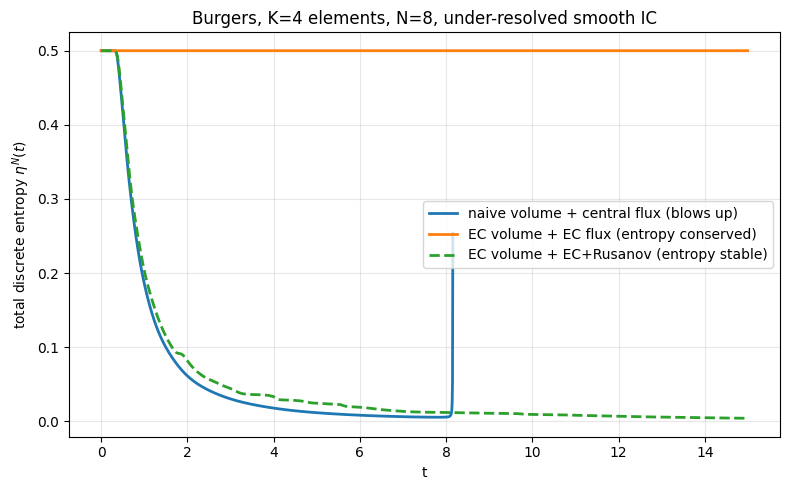

In [10]:

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(t_plain, e_plain, label="naive volume + central flux (blows up)", lw=2)
ax.plot(t_ec, e_ec, label="EC volume + EC flux (entropy conserved)", lw=2)
ax.plot(t_ecd, e_ecd, label="EC volume + EC+Rusanov (entropy stable)", lw=2, ls='--')
ax.set_xlabel("t")
ax.set_ylabel(r"total discrete entropy $\eta^N(t)$")
ax.set_title(f"Burgers, K={K} elements, N={N}, under-resolved smooth IC")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



The naive scheme's entropy trace simply stops -- it has blown up. The two flux-differencing
schemes both survive the same run: the pure EC configuration keeps total entropy essentially
exactly constant (Theorem 5.1's exact telescoping, now demonstrated over a full simulation and
many elements rather than one hand-worked node), and the entropy-stable configuration lets entropy
decrease, as it must once the initially-smooth data steepens into a genuine shock.

This is a small-scale version of exactly what Section 6 (citing Gassner, Winters & Kopriva 2016)
describes for the compressible Euler equations: interior aliasing error alone, with no
discontinuity anywhere at $t=0$, is enough to crash an otherwise perfectly consistent, conservative
scheme, and flux differencing with an entropy-compatible two-point flux is what fixes it.



## 6. Shock Tube: Roe vs. Godunov, Reproducing the Notes' Worked Example

Section 2 of the notes works through, by hand, the classic Roe-vs-Godunov comparison on the
degenerate (first-order finite-volume) case of the scheme -- Example 3.12's "$N=0$" limit. Roe's
flux freezes an *inadmissible* stationary shock in place forever; Godunov's flux correctly resolves
the rarefaction fan the true solution actually develops. We reproduce this directly, and then check
the contrasting case: a genuinely admissible (compressive) shock, where Roe is *not* wrong.


In [11]:

def flux_roe_burgers(uL, uR):
    a_roe = 0.5 * (uL + uR)   # Roe-average wave speed for Burgers' flux
    return F_burgers(uL) if a_roe >= 0 else F_burgers(uR)

def flux_godunov_burgers(uL, uR):
    if uL <= uR:
        return 0.0 if (uL <= 0 <= uR) else min(F_burgers(uL), F_burgers(uR))
    else:
        return max(F_burgers(uL), F_burgers(uR))

def run_fv(u0, flux_fn, K, dx, dt, nsteps):
    u = u0.copy()
    for _ in range(nsteps):
        fnum = np.array([flux_fn(u[(i-1) % K], u[i % K]) for i in range(K+1)])
        u = u - (dt/dx) * (fnum[1:] - fnum[:-1])
    return u

K, dx = 60, 1.0
x_fv = (np.arange(K) + 0.5)*dx - K*dx/2
dt, nsteps = 0.4*dx, 25


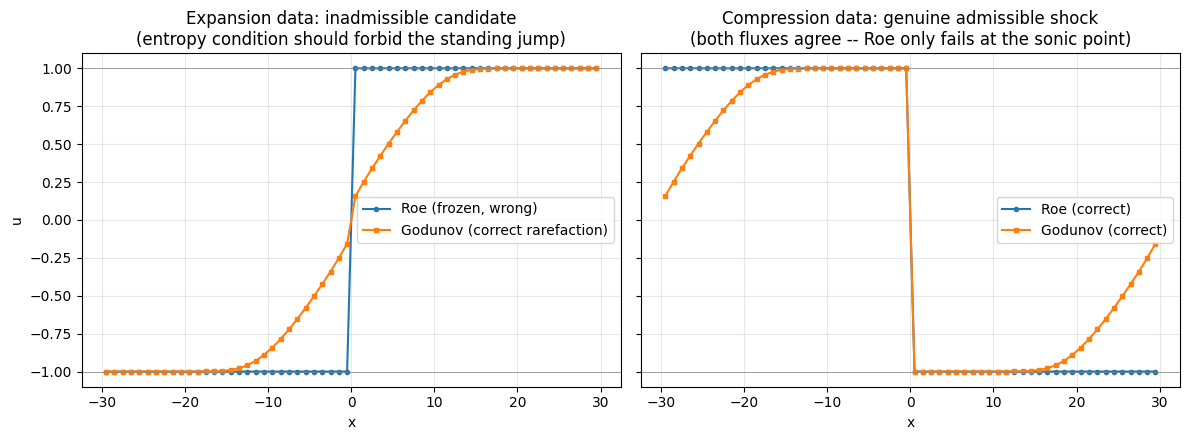

Expansion case, a few cells either side of the interface:
  Roe:      [-1. -1. -1.  1.  1.  1.]
  Godunov:  [-0.34  -0.252 -0.156  0.156  0.252  0.34 ]

Compression case, a few cells either side of the interface:
  Roe:      [ 1.  1.  1. -1. -1. -1.]
  Godunov:  [ 1.  1.  1. -1. -1. -1.]


In [12]:

# Case 1: EXPANSION data (u- = -1, u+ = +1) -- the inadmissible-candidate case from Section 2.1
u0_expand = np.where(x_fv < 0, -1.0, 1.0)
u_roe_e = run_fv(u0_expand, flux_roe_burgers, K, dx, dt, nsteps)
u_god_e = run_fv(u0_expand, flux_godunov_burgers, K, dx, dt, nsteps)

# Case 2: COMPRESSION data (u- = +1, u+ = -1) -- a genuine, admissible standing shock
u0_compress = np.where(x_fv < 0, 1.0, -1.0)
u_roe_c = run_fv(u0_compress, flux_roe_burgers, K, dx, dt, nsteps)
u_god_c = run_fv(u0_compress, flux_godunov_burgers, K, dx, dt, nsteps)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(x_fv, u_roe_e, 'o-', ms=3, label="Roe (frozen, wrong)")
axes[0].plot(x_fv, u_god_e, 's-', ms=3, label="Godunov (correct rarefaction)")
axes[0].axhline(-1, color='gray', lw=0.5); axes[0].axhline(1, color='gray', lw=0.5)
axes[0].set_title("Expansion data: inadmissible candidate\n(entropy condition should forbid the standing jump)")
axes[0].set_xlabel("x"); axes[0].set_ylabel("u"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(x_fv, u_roe_c, 'o-', ms=3, label="Roe (correct)")
axes[1].plot(x_fv, u_god_c, 's-', ms=3, label="Godunov (correct)")
axes[1].axhline(-1, color='gray', lw=0.5); axes[1].axhline(1, color='gray', lw=0.5)
axes[1].set_title("Compression data: genuine admissible shock\n(both fluxes agree -- Roe only fails at the sonic point)")
axes[1].set_xlabel("x"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Expansion case, a few cells either side of the interface:")
print("  Roe:     ", np.round(u_roe_e[K//2-3:K//2+3], 3))
print("  Godunov: ", np.round(u_god_e[K//2-3:K//2+3], 3))
print()
print("Compression case, a few cells either side of the interface:")
print("  Roe:     ", np.round(u_roe_c[K//2-3:K//2+3], 3))
print("  Godunov: ", np.round(u_god_c[K//2-3:K//2+3], 3))



Exactly the behaviour the notes describe: on the expansion data, Roe's flux is an exact fixed
point -- the standing discontinuity never moves, reproducing the entropy-violating jump identified
in Section 1.5's worked example -- while Godunov's flux correctly spreads it into a rarefaction
fan. On the compression data, where the standing shock genuinely *is* the admissible solution, Roe
and Godunov agree: Roe's flux only fails at the sonic point of an inadmissible candidate, not on
admissible shocks in general (Remark 2.1 in the notes).

**Where to go next**, following the same order the notes build in:

- Swap this finite-volume shock tube for the full multi-element DGSEM from Section 5, with an
  entropy-stable interface flux, and check the shock is captured without oscillation and that
  entropy is genuinely *produced* (not conserved) across it.
- Extend `F_burgers`/`F_vol_EC_burgers`/`U_entropy` to a system (compressible Euler), using the
  Ismail–Roe or Chandrashekar entropy-conservative flux referenced in Section 5.3 of the notes.
- Only once that's solid, move to the 2D curvilinear mapping of Section 3 -- the Gordon–Hall map,
  metric identities, and isoparametric rule are a genuinely separate piece of complexity from the
  entropy-stability logic developed and tested here, and are worth keeping decoupled for as long
  as possible.
